In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(42); tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [4]:
num_notes       = 50     # vocabulary size (given)
sequence_length = 30     # notes per melody (given)
num_sequences   = 1000   # number of melodies (given)

data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))  # (given)

# Q1a) input = all notes except the LAST;  target = all notes except the FIRST
x_train = data[:, :-1]  # TODO (Q1a): data[:, :-1]
y_train = data[:, 1:] # TODO (Q1a): data[:, 1:]

# Q1b) one-hot encode both to shape (samples, 29, 50)
NUM_CLASSES =50  # TODO (Q1b): how many distinct notes?
x_train = to_categorical(x_train, num_classes=NUM_CLASSES)
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)

print("x_train:", x_train.shape, " y_train:", y_train.shape)   # expect (1000, 29, 50) each

x_train: (1000, 29, 50)  y_train: (1000, 29, 50)


In [5]:
assert x_train.shape == (1000, 29, 50), "x_train shape should be (1000, 29, 50)"
assert y_train.shape == (1000, 29, 50), "y_train shape should be (1000, 29, 50)"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


In [6]:
model = models.Sequential()
model.add(layers.Input(shape=(sequence_length-1, num_notes)))        # (29, 50)  (given)

# Q2a) first Bidirectional LSTM: 128 units, return a sequence
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))  # TODO (Q2a)

# Q2b) second Bidirectional LSTM: same settings
model.add(layers.Bidirectional(layers.LSTM(128,return_sequences=True)))   # TODO (Q2b): another Bidirectional(LSTM(128, return_sequences=True))

# Q2c) TimeDistributed Dense output: one softmax classifier per step
model.add(layers.TimeDistributed(layers.Dense(num_notes, activation='softmax')))  # TODO (Q2c)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 29, 256)        │       183,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 29, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 29, 50)         │        12,850 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,386 (2.25 MB)

 Trainable params: 590,386 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Q3a) compile for multi-class, one-hot targets
model.compile(optimizer=Adam(learning_rate=0.001),   # TODO (Q3a): 0.001
              loss='categorical_crossentropy',                             # TODO (Q3a): 'categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a 20% validation split
history = model.fit(x_train, y_train,
                    epochs=20,            # TODO (Q3b): 20
                    batch_size=64,        # TODO (Q3b): 64
                    validation_split=0.2)  # TODO (Q3b): 0.2

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 87ms/step - accuracy: 0.1040 - loss: 3.8857 - val_accuracy: 0.1698 - val_loss: 3.8467
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.1597 - loss: 3.7785 - val_accuracy: 0.1047 - val_loss: 3.6747
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1181 - loss: 3.5284 - val_accuracy: 0.1345 - val_loss: 3.4011
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1616 - loss: 3.2280 - val_accuracy: 0.1807 - val_loss: 3.1007
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.2095 - loss: 2.8742 - val_accuracy: 0.2248 - val_loss: 2.7739
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2723 - loss: 2.5118 - val_accuracy: 0.3019 - val_loss: 2.3651
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3431 - loss: 2.1302 - val_accuracy: 0.3824 - val_loss: 2.0040
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.4255 - loss: 1.7746 - val_accuracy: 0.4716 - 

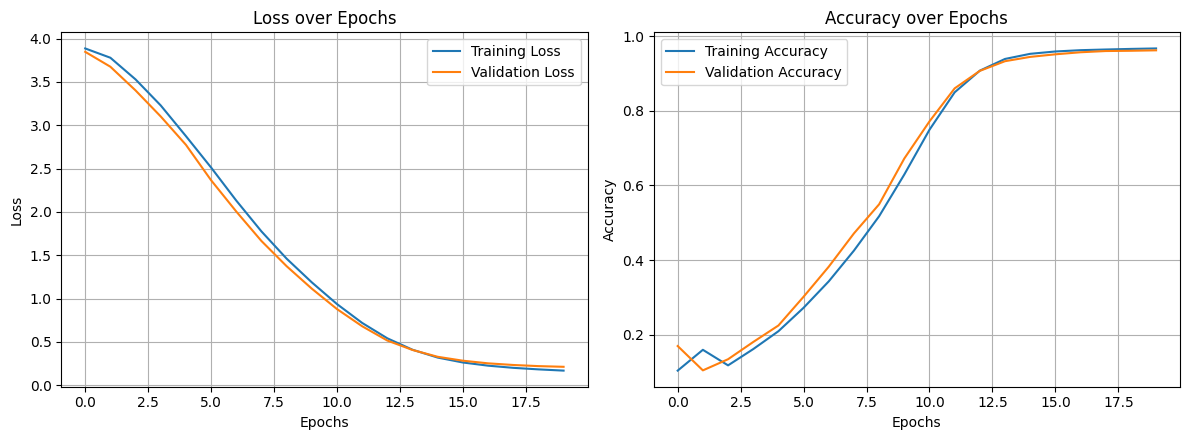

In [12]:
plt.figure(figsize=(12,4.5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'],     label='Training Loss')
plt.plot(history.history['val_loss'],       label='Validation Loss')   # TODO (Q4a): val loss key
plt.title('Loss over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'],       label='Validation Accuracy')  # TODO (Q4b): val acc key
plt.title('Accuracy over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid()

plt.tight_layout(); plt.show()

In [19]:
def generate_music(model, start_sequence, num_generated_notes=50):
    generated = []
    current_sequence = start_sequence
    for _ in range(num_generated_notes):
        pred = model.predict(current_sequence, verbose=0)      # (1, 29, 50)

        # Q5a) pick the most likely note at the LAST time step
        next_note = np.argmax(pred[:, -1, :], axis=-1)  # TODO (Q5a): np.argmax(pred[:, -1, :], axis=-1)
        generated.append(int(next_note[0]))

        # Q5b) slide the window: drop the first step, append the new note (one-hot)
        oh = to_categorical(next_note, num_classes=num_notes).reshape(1, 1, num_notes)
        current_sequence =  np.concatenate([current_sequence[:, 1:, :], oh], axis=1) # TODO (Q5b): np.concatenate([current_sequence[:, 1:, :], oh], axis=1)
    return generated

# seed window (given)
start = np.random.randint(0, num_notes, size=(1, sequence_length-1))
start = to_categorical(start, num_classes=num_notes)

generated_music = generate_music(model, start, num_generated_notes=50)
print("Generated:", generated_music)

Generated: [43, 19, 19, 19, 9, 9, 9, 9, 37, 37, 37, 37, 8, 8, 8, 8, 8, 8, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26]


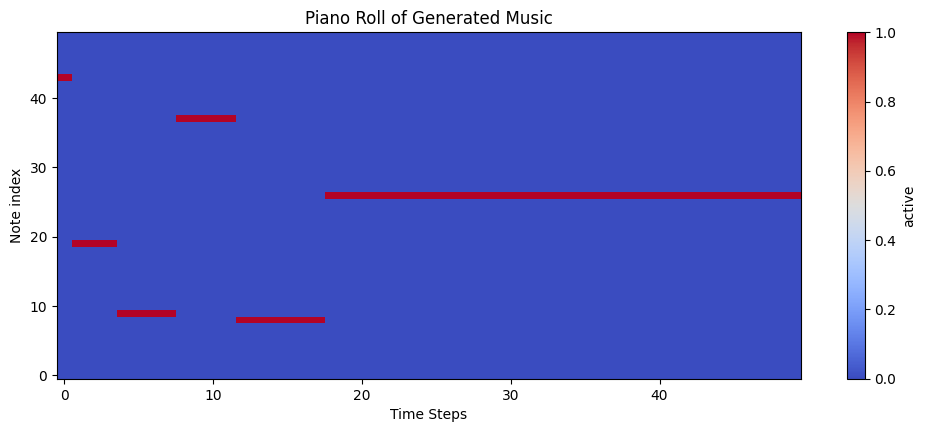

In [20]:
piano_roll = np.zeros((num_notes, len(generated_music)))
for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1   # TODO (Q6): which row is the active note at time t?

plt.figure(figsize=(12,4.5))
plt.imshow(piano_roll, aspect='auto', cmap='coolwarm', origin='lower', interpolation='nearest')
plt.colorbar(label='active'); plt.title('Piano Roll of Generated Music')
plt.xlabel('Time Steps'); plt.ylabel('Note index'); plt.show()

In [18]:
import numpy as np
from IPython.display import Audio
audio = np.concatenate([np.sin(2 * np.pi * (440.0 * (2.0 ** (((48 + n) - 69.0) / 12.0))) * np.linspace(0, 0.25, 2000, False)) for n in generated_music])
Audio(audio, rate=8000)

### Task 7 — Analysis Answers

1. **What would break if you set `return_sequences=False` on the first layer?**
   If the first Bi-LSTM layer has `return_sequences=False`, it will only return the output of the last timestep (a 2D tensor of shape `(batch, units)`). The second Bi-LSTM layer expects a 3D sequential temporal input of shape `(batch, timesteps, features)`. This mismatch will raise a `ValueError` during model compilation/building.

2. **Why is the first Bi-LSTM's output width 256 when the LSTM has 128 units?**
   A Bidirectional wrapper processes the sequence both forwards and backwards with two independent LSTM layers (each having 128 units). By default, their outputs are concatenated, resulting in a width of `128 * 2 = 256` features.

3. **What does `TimeDistributed(Dense(50))` do that a plain `Dense(50)` would not?**
   `TimeDistributed` explicitly applies the same `Dense` layer independently to each individual timestep in the sequence. In modern Keras, a plain `Dense(50)` applied to a 3D tensor automatically applies the dense layer to the last axis (timestep-wise) as well. However, `TimeDistributed` ensures a strict sequence-to-sequence structure visually and keeps architectural compatibility clear.

4. **You trained on random notes, yet accuracy reaches ~96%. Explain the mechanism.**
   Because the model is Bidirectional, the backward LSTM passes information from the future (right to left). When predicting the target note at timestep $t$ (which is $x_{t+1}$ because $y_t = x_{t+1}$), the backward layer can simply look ahead and read $x_{t+1}$ directly from the future input. The model trivializes the task by copying future inputs to present targets.

5. **Why is a bidirectional model a poor choice for autoregressive generation, and what two changes would make this an honest music generator?**
   * **Why it is poor:** During step-by-step autoregressive generation, there is no "future" sequence available to look at. The backward LSTM cannot function as intended, leading to static or repetitive generation patterns (as seen in the flatline pattern of the piano roll).
   * **Two changes:**
     1. Use **unidirectional** LSTMs (remove the `Bidirectional` wrapper) so that the model only depends on past notes.
     2. Use **causal masking** or teach the model using proper teacher forcing without look-ahead capability.